In [1]:
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64


In [2]:
# CÂU a & b
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

iris = load_iris()
print("Tên các thuộc tính (features):", iris.feature_names)
print("Tên các lớp (targets):", iris.target_names)
print("Kích thước data:", iris.data.shape, "- Kích thước target:", iris.target.shape)

print("\n5 mẫu dữ liệu đầu tiên:")
for i in range(5):
    print(f"Mẫu {i+1}: {iris.data[i]} -> Nhãn: {iris.target[i]} ({iris.target_names[iris.target[i]]})")

df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
print("\nThống kê cơ bản (describe):")
print(df_iris.describe())

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Tên các thuộc tính (features): ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Tên các lớp (targets): ['setosa' 'versicolor' 'virginica']
Kích thước data: (150, 4) - Kích thước target: (150,)

5 mẫu dữ liệu đầu tiên:
Mẫu 1: [5.1 3.5 1.4 0.2] -> Nhãn: 0 (setosa)
Mẫu 2: [4.9 3.  1.4 0.2] -> Nhãn: 0 (setosa)
Mẫu 3: [4.7 3.2 1.3 0.2] -> Nhãn: 0 (setosa)
Mẫu 4: [4.6 3.1 1.5 0.2] -> Nhãn: 0 (setosa)
Mẫu 5: [5.  3.6 1.4 0.2] -> Nhãn: 0 (setosa)

Thống kê cơ bản (describe):
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000

In [3]:
# CÂU c & d
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

X = iris.data / np.max(iris.data, axis=0) # Chuẩn hóa chia cho max từng cột
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Tập huấn luyện X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Tập kiểm thử X_test: {X_test.shape}, y_test: {y_test.shape}")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Tập huấn luyện X_train: (120, 4), y_train: (120,)
Tập kiểm thử X_test: (30, 4), y_test: (30,)


Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Accuracy Decision Tree: 93.33%

Classification Report Decision Tree:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



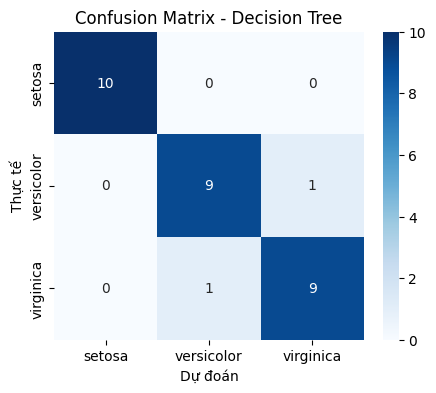

In [4]:
# CÂU e
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)

print(f"Accuracy Decision Tree: {accuracy_score(y_test, y_pred_dt)*100:.2f}%\n")
print("Classification Report Decision Tree:\n", classification_report(y_test, y_pred_dt, target_names=iris.target_names))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Accuracy Naïve Bayes: 96.67%

Classification Report Naïve Bayes:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



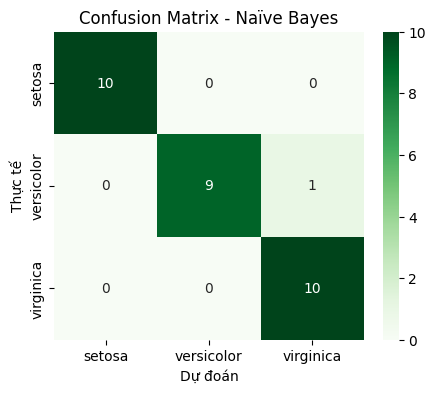

In [5]:
# CÂU f
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

print(f"Accuracy Naïve Bayes: {accuracy_score(y_test, y_pred_nb)*100:.2f}%\n")
print("Classification Report Naïve Bayes:\n", classification_report(y_test, y_pred_nb, target_names=iris.target_names))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_nb), annot=True, fmt='d', cmap='Greens', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Confusion Matrix - Naïve Bayes")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Accuracy KNN: 93.33%

Classification Report KNN:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



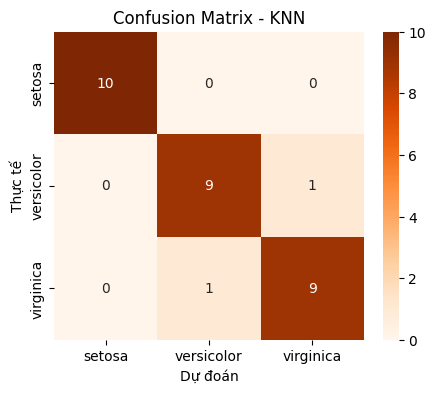

In [6]:
# CÂU g
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

print(f"Accuracy KNN: {accuracy_score(y_test, y_pred_knn)*100:.2f}%\n")
print("Classification Report KNN:\n", classification_report(y_test, y_pred_knn, target_names=iris.target_names))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Oranges', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Confusion Matrix - KNN")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


120/120 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.3750 - loss: 1.1138
Epoch 2/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7000 - loss: 1.0340
Epoch 3/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7750 - loss: 0.8808
Epoch 4/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7583 - loss: 0.7241
Epoch 5/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7750 - loss: 0.5984
Epoch 6/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9167 - loss: 0.5026
Epoch 7/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9000 - loss: 0.4244
Epoch 8/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.3737
Epoch 9/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9667 - loss: 0.3290
Epoch 10/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9583 - loss: 0.2980
Epoch 11/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9667 - loss: 0.2697
Epoch 12/100
120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

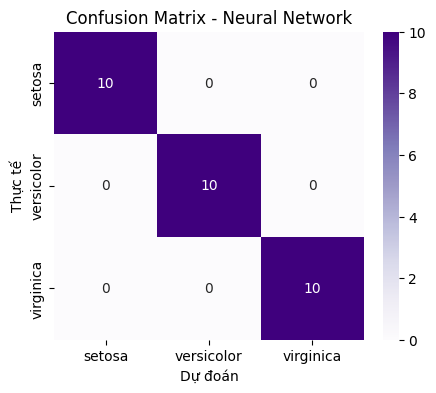

In [7]:
# CÂU h
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

# Xây dựng mô hình 2 hidden layers (10 và 20 nơ-ron), output 3 nơ-ron Softmax
nn_model = Sequential([
    Dense(10, activation='relu', input_shape=(4,)),
    Dense(20, activation='relu'),
    Dense(3, activation='softmax')
])

nn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
nn_model.fit(X_train, y_train, epochs=100, batch_size=1, verbose=1)

y_prob_nn = nn_model.predict(X_test)
y_pred_nn = np.argmax(y_prob_nn, axis=1)

print(f"\nAccuracy Neural Network: {accuracy_score(y_test, y_pred_nn)*100:.2f}%\n")
print("Classification Report Neural Network:\n", classification_report(y_test, y_pred_nn, target_names=iris.target_names))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_nn), annot=True, fmt='d', cmap='Purples', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("Confusion Matrix - Neural Network")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

In [8]:
# CÂU i & j
print("Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64")

new_samples = np.array([
    [6.2, 2.9, 4.3, 1.3],
    [5.1, 3.5, 1.4, 0.2],
    [7.3, 2.8, 6.4, 2.1]
])
# Chuẩn hóa 3 mẫu mới theo cùng tỉ lệ max của iris.data
new_samples_norm = new_samples / np.max(iris.data, axis=0)

pred_dt = dt_model.predict(new_samples_norm)
pred_nb = nb_model.predict(new_samples_norm)
pred_knn = knn_model.predict(new_samples_norm)
pred_nn = np.argmax(nn_model.predict(new_samples_norm), axis=1)

print("KẾT QUẢ DỰ ĐOÁN 3 MẪU MỚI:")
for i in range(3):
    print(f"\nMẫu {i+1} {new_samples[i]}:")
    print(f" - Decision Tree: {iris.target_names[pred_dt[i]]}")
    print(f" - Naïve Bayes:   {iris.target_names[pred_nb[i]]}")
    print(f" - KNN:           {iris.target_names[pred_knn[i]]}")
    print(f" - Neural Net:    {iris.target_names[pred_nn[i]]}")

Họ và tên: Trần Thanh Ngân - MSSV: 6451071048 - Lớp: CNTT K64
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
KẾT QUẢ DỰ ĐOÁN 3 MẪU MỚI:

Mẫu 1 [6.2 2.9 4.3 1.3]:
 - Decision Tree: versicolor
 - Naïve Bayes:   versicolor
 - KNN:           versicolor
 - Neural Net:    versicolor

Mẫu 2 [5.1 3.5 1.4 0.2]:
 - Decision Tree: setosa
 - Naïve Bayes:   setosa
 - KNN:           setosa
 - Neural Net:    setosa

Mẫu 3 [7.3 2.8 6.4 2.1]:
 - Decision Tree: virginica
 - Naïve Bayes:   virginica
 - KNN:           virginica
 - Neural Net:    virginica
